# `fig-results-laptops-slopes`: Consumer rights (laptops) OLS treatment effects by attribute, off-the-shelf versus pooled choice training

In [1]:
from pathlib import Path
import sys

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ASSET_NAME = "fig-results-laptops-slopes"
ASSET_DIR = Path.cwd()
PAPER_DIR = ASSET_DIR.parent
SRC_DIR = PAPER_DIR / "src"
if not (SRC_DIR / "microdata_analysis.py").is_file():
    raise FileNotFoundError(f"Open this notebook from assets/; {SRC_DIR} has no microdata_analysis.py")
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import microdata_analysis as ma

print(f"Outputs go to {ASSET_DIR / ASSET_NAME}.*")

import matplotlib.lines

Outputs go to /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/fig-results-laptops-slopes.*


## Run design

In [2]:
RUN_ROOTS = (PAPER_DIR / "runs-rorqual", PAPER_DIR / "runs-nibi")
MODELS = ("kev-0.8b", "kev-4b", "kev-9b")
BASE_SLUG = "row1_base_untrained"
TRAINED_SLUGS = ("row2b_wu_ce_oracle", "row3_berke_ce_only", "row5_full_berke_wu_ce_oracle")
VALIDATORS = ("kriner2026", "grummon2025")

ctx = ma.load_microdata_context(
    run_roots=RUN_ROOTS,
    models=MODELS,
    base_slug=BASE_SLUG,
    trained_slugs=TRAINED_SLUGS,
    validators=VALIDATORS,
)
display(ctx.status_grid)

,kev-0.8b,kev-4b,kev-9b
regime,,,
row1_base_untrained,step 0 [test_best ✓],step 0 [test_best ✓],step 0 [test_best ✓]
row2b_wu_ce_oracle,finished (@640/1395) [test_best ✓],finished (@416/1395) [test_best ✓],finished (@928/1395) [test_best ✓]
row3_berke_ce_only,finished (@1152/2730) [test_best ✓],finished (@544/2730) [test_best ✓],finished (@256/2730) [test_best ✓]
row5_full_berke_wu_ce_oracle,finished (@1600/4125) [test_best ✓],finished (@1472/4125) [test_best ✓],finished (@1600/4125) [test_best ✓]


## Labels and formatting (edit wording here)

In [3]:
BETAS_FIELD = "kantorowicz_betas_by_model"
MODEL_LABELS = {"kev-0.8b": "KEV-0.8B", "kev-4b": "KEV-4B", "kev-9b": "KEV-9B"}

# Bars per row, top to bottom; legend order follows this dict.
COMPARED_REGIMES = {
    BASE_SLUG: "Off-the-shelf",
    "row5_full_berke_wu_ce_oracle": "Drones + Electricity",
}
REGIME_COLORS = {
    BASE_SLUG: "#9A9893",
    "row5_full_berke_wu_ce_oracle": "#1B365D",
}
BAR_Y_OFFSETS = (-0.14, 0.14)
BAR_WIDTH = 5.0
HUMAN_LABEL = "Human (OLS)"
HUMAN_TICK_HALF_HEIGHT = 0.34

# Optional renames, raw term -> y-axis text. Terms not listed are shown as they are (after TERM_PREFIX is dropped).
TERM_LABELS = {}

X_LABEL = r"OLS treatment effect ($\beta$)"

TEXT_COLOR = "#2B2B2B"
REF_LINE_COLOR = "#6E6A64"
GRID_COLOR = "#D4D2CC"

PANEL_TITLE_SIZE = 11
TERM_LABEL_SIZE = 9
LEGEND_SIZE = 9.0
LEFT_PAD = 3.2
ROW_HEIGHT = 0.38
LEGEND_X = 0.60

## Rows (terms) in plot order

In [4]:
# Laptop rows only; the prefix is dropped from the y-axis text.
TERM_PREFIX = "Computers | "

raw_terms = list(getattr(ctx, BETAS_FIELD)[MODELS[0]][BASE_SLUG].index)
terms = [term for term in raw_terms if term.startswith(TERM_PREFIX)]
if not terms:
    raise ValueError(f"No Consumer rights terms start with {TERM_PREFIX!r}")
default_labels = {term: term[len(TERM_PREFIX):] for term in terms}

# Dashed line under the price rows.
n_price = 0
for term in terms:
    if default_labels[term].startswith("Price:"):
        n_price += 1
if n_price == 0:
    raise ValueError(f"No Price terms among {terms}")
divider_ys = (n_price - 0.5,)
print(f"{len(terms)} terms; {n_price} price")

19 terms; 2 price


## Draw

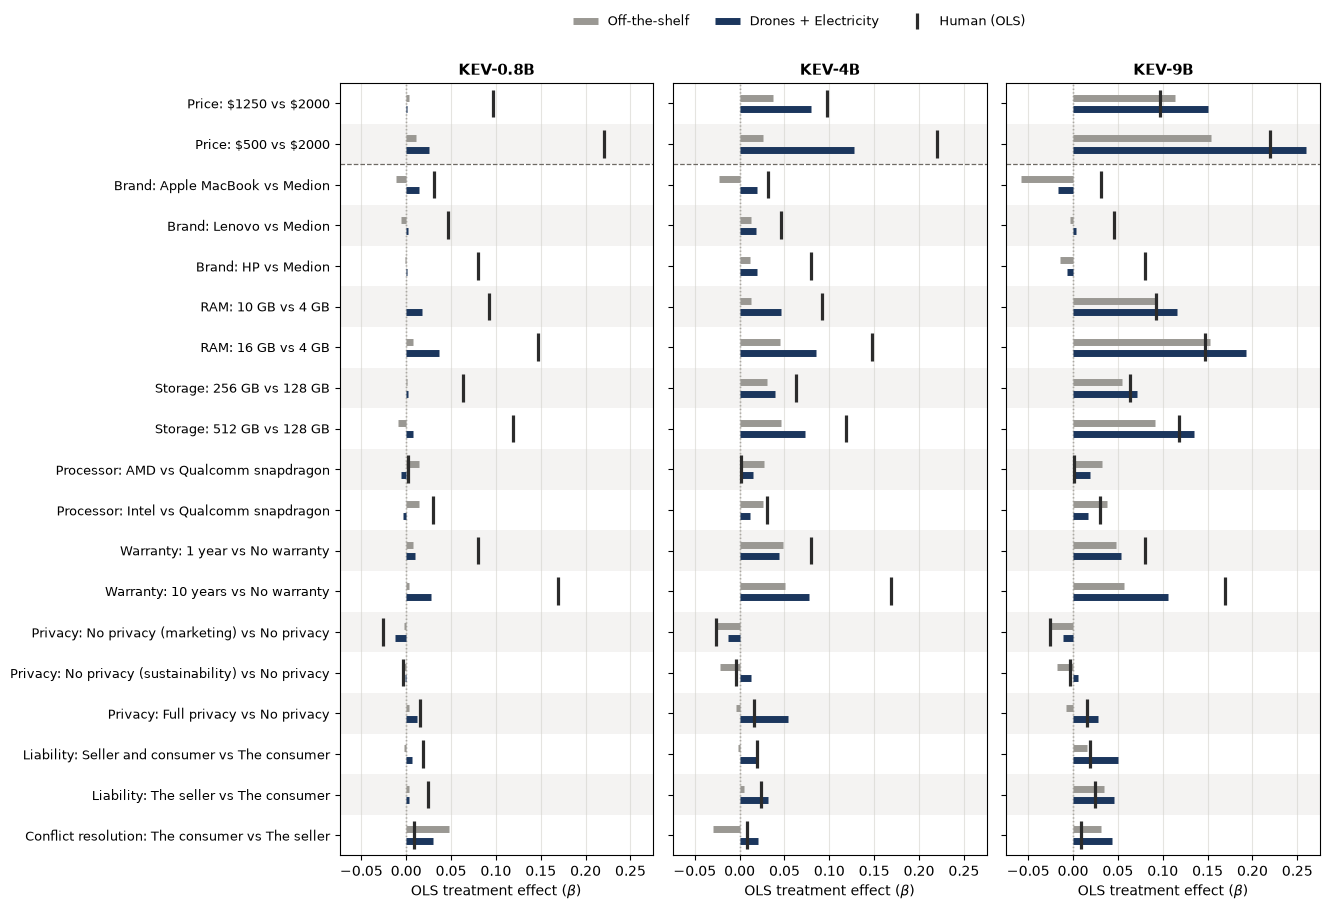

In [5]:
if len(BAR_Y_OFFSETS) != len(COMPARED_REGIMES):
    raise ValueError(f"{len(BAR_Y_OFFSETS)} bar offsets for {len(COMPARED_REGIMES)} regimes")
shown_labels = []
for term in terms:
    if term in TERM_LABELS:
        shown_labels.append(TERM_LABELS[term])
    else:
        shown_labels.append(default_labels[term])

y_positions = np.arange(len(terms), dtype=float)
fig_height = max(3.6, ROW_HEIGHT * len(terms) + 1.8)
fig, axes = plt.subplots(
    1,
    len(MODELS),
    figsize=(3.4 * len(MODELS) + LEFT_PAD, fig_height),
    sharey=True,
    sharex=True,
    squeeze=False,
)
axes = axes[0]

for ax, model_slug in zip(axes, MODELS):
    betas_by_regime = getattr(ctx, BETAS_FIELD)[model_slug]
    ax.axvline(0.0, color=REF_LINE_COLOR, linewidth=1.0, linestyle=":", zorder=1)
    for divider_y in divider_ys:
        ax.axhline(divider_y, color=REF_LINE_COLOR, linestyle="--", linewidth=0.9, zorder=2)
    for y in y_positions:
        if int(y) % 2 == 1:
            ax.axhspan(y - 0.5, y + 0.5, color=GRID_COLOR, alpha=0.25, zorder=0, linewidth=0)

    for (regime_slug, regime_label), y_offset in zip(COMPARED_REGIMES.items(), BAR_Y_OFFSETS):
        model_values = betas_by_regime[regime_slug].loc[terms, "model_pop_beta"].to_numpy(dtype=float)
        ax.hlines(y_positions + y_offset, 0.0, model_values, color=REGIME_COLORS[regime_slug], linewidth=BAR_WIDTH, zorder=3, label=regime_label)

    human_values = betas_by_regime[BASE_SLUG].loc[terms, "human_pop_beta"].to_numpy(dtype=float)
    ax.vlines(human_values, y_positions - HUMAN_TICK_HALF_HEIGHT, y_positions + HUMAN_TICK_HALF_HEIGHT, color=TEXT_COLOR, linewidth=2.3, zorder=4)

    ax.set_title(MODEL_LABELS[model_slug], fontsize=PANEL_TITLE_SIZE, fontweight="bold")
    ax.set_xlabel(X_LABEL)
    ax.grid(axis="x", color=GRID_COLOR, alpha=0.6)

# "$" would start matplotlib math mode, so it is escaped in term labels.
escaped_labels = [label.replace("$", r"\$") for label in shown_labels]
axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(escaped_labels, fontsize=TERM_LABEL_SIZE)
axes[0].set_ylim(-0.5, len(terms) - 0.5)
axes[0].invert_yaxis()

handles, labels = axes[0].get_legend_handles_labels()
human_handle = matplotlib.lines.Line2D([], [], color=TEXT_COLOR, marker="|", linestyle="None", markersize=11, markeredgewidth=2.3)
handles.append(human_handle)
labels.append(HUMAN_LABEL)
if len(terms) <= 6:
    top_rect = 0.90
elif len(terms) <= 14:
    top_rect = 0.94
else:
    top_rect = 0.96
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(LEGEND_X, 1.01), ncol=len(COMPARED_REGIMES) + 1, fontsize=LEGEND_SIZE, frameon=False)
fig.tight_layout(rect=(0.0, 0.0, 1.0, top_rect))

## Save `fig-results-laptops-slopes.png` and `.pdf` (the manuscript points here)

In [6]:
for extension in ("png", "pdf"):
    figure_path = ASSET_DIR / f"{ASSET_NAME}.{extension}"
    fig.savefig(figure_path, dpi=300, bbox_inches="tight")
    print(f"Saved {figure_path}")
plt.show()

Saved /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/fig-results-laptops-slopes.png
Saved /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/manuscript-training-assets/fig-results-laptops-slopes.pdf
